# UZK: GRU без автоэнкодера

Запускайте из корня проекта с ядром `.venv` после `uv sync`.
Конфиг: `configs/uzk_gru.yaml`.

Пайплайн исключает заданные интервалы, масштабирует признаки, выбирает восемь
признаков из конфига, выравнивает будущую цель и формирует окна для GRU.
Скейлеры и GRU обучаются в этом запуске. Test вычисляется после обучения.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from feature_selector import ExperimentRun, load_config, run_experiment
from feature_selector.artifacts import load_run
from feature_selector.data import load_data
from feature_selector.evaluation import regression_metrics
from feature_selector.visualization import plot_split_predictions, plot_training_history

config = load_config(Path("configs/uzk_gru.yaml"))


## Обучение GRU

GRU прогнозирует `UZK.Q.81AY00108.FINALPOINT` на следующий шаг.
Модель обучается только на окнах с известной целью; её скейлер обучается
на этих train-целях. Validation используется для выбора весов.
Запуск сохраняет весь обученный пайплайн в отдельный каталог.


In [2]:
run = run_experiment(config)
print(f"Results: {run.artifact_dir}")
print("GRU train windows:", sum(batch["samples"] for batch in run.model.history_[0]["batches"]))
pd.DataFrame.from_dict(run.metrics, orient="index")


Results: /mnt/data/Projects/feature_selector_v3/runs/20261018T021750822310Z-c7757a7f
GRU train windows: 222


,mae,rmse,r2,pearson,n,notes
train,3.023207,4.094819,0.965096,0.983712,222,{}
validation,2.626125,3.746399,-0.040128,0.224888,47,{}


## История обучения GRU

Loss GRU — MSE прогнозирования после масштабирования цели.
Показаны train loss и validation loss по эпохам; линия отмечает выбранную эпоху.
Метрики в таблицах рассчитаны в исходных единицах цели.


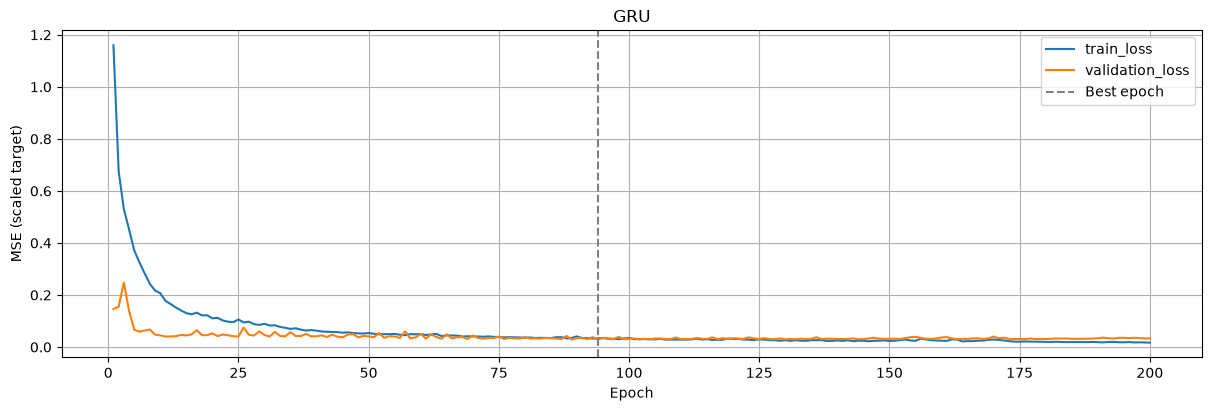

In [3]:
ax = plot_training_history(
    run.model.history_, run.model.best_epoch_, title="GRU"
)
ax.set_ylabel("MSE (scaled target)")
plt.show()


## Загрузка и явная оценка test

Загружаем сохранённый пайплайн и вычисляем test без дообучения.
Этот вызов не изменяет автоматически сохранённые train/validation-отчёты.


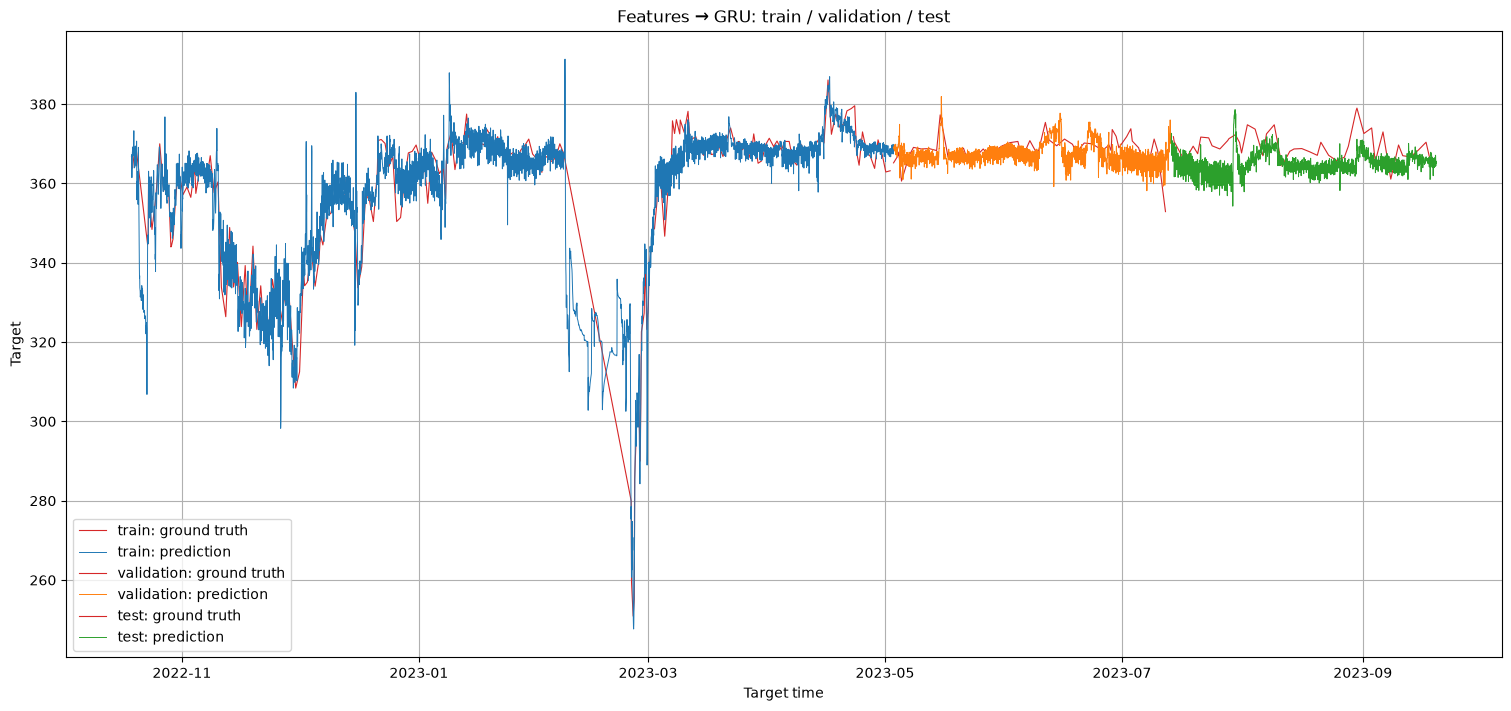

,mae,rmse,r2,pearson,n,notes
train,3.023207,4.094819,0.965096,0.983712,222,{}
validation,2.626125,3.746399,-0.040128,0.224888,47,{}
test,4.436702,5.396965,-1.407520,0.335976,44,{}


In [4]:
saved = load_run(run.artifact_dir)
assert isinstance(saved, ExperimentRun)
data = load_data(**config.data)
test_report = saved.predict(data, split="test")
observed = test_report.dropna(subset=["y_true"])
test_metrics = regression_metrics(observed.y_true, observed.y_pred)
reports = {**run.predictions, "test": test_report}
plot_split_predictions(reports, title="Features → GRU: train / validation / test")
plt.show()
pd.DataFrame.from_dict({**run.metrics, "test": test_metrics}, orient="index")


## Loss по тренировочным батчам

Batch loss доступен в `history_` и записывается в JSONL и TensorBoard.
Команда `uv run tensorboard --logdir runs` открывает мониторинг обучения.
Ход обучения смотрите в **Scalars**, итоговые метрики — в `metrics.json`.


,epoch,batch,samples,train_loss,step,learning_rate
0,1,1,128,1.582750,1,0.01
1,1,2,94,0.584474,2,0.01
2,2,1,128,0.817214,3,0.01
3,2,2,94,0.483144,4,0.01
4,3,1,128,0.448880,5,0.01


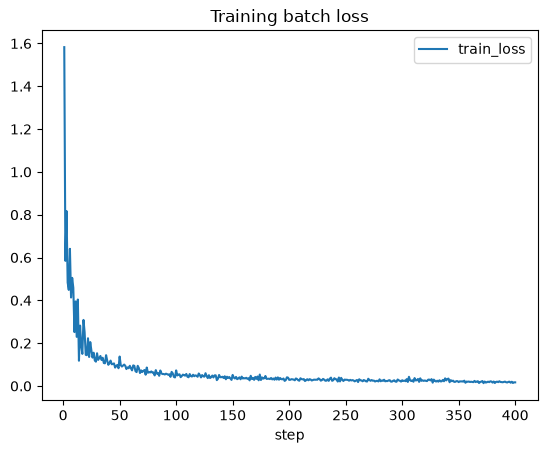

In [5]:
batch_history = pd.DataFrame([
    {"epoch": epoch["epoch"], **batch}
    for epoch in run.model.history_ for batch in epoch["batches"]
])
display(batch_history.head())
if not batch_history.empty:
    batch_history.plot(x="step", y="train_loss", title="Training batch loss")
    plt.show()
